# Phase 4 — Hierarchical Divisive Clustering (DIANA)
**Student:** Jeswin Tobias J &nbsp;|&nbsp; **Roll No:** CS23I1013
**Input:** `outputs/daily_profiles.csv` — 364 days × 72 zone-hour values (Phase 1)

### Why DIANA (and not KNN) for this dataset
The question asks for KNN **or** DIANA, "whichever is relevant for the data set". The Tetouan data has **no class label**: the task is to discover structure, not predict a given class. So **unsupervised DIANA** is the relevant choice. KNN would need an artificial label made from the power columns.

### DIANA in brief
1. Start with **all objects in one cluster**.
2. Split the cluster with the **largest diameter** (max pairwise distance).
3. **Splinter group:** the object with the largest mean distance to the rest leaves first. Then repeatedly move the object for which *(mean distance to the old group − mean distance to the splinter group)* is largest and > 0.
4. Repeat until every object is alone. Split height = diameter of the cluster being split → **dendrogram**.

### Design decisions (assumed & stated)
| Decision | Choice | Reason |
|---|---|---|
| Object | **one day** (364) | distance matrix: 10-min rows ≈ 22 GB, hourly ≈ 0.6 GB, daily ≈ 1 MB; the question is about day types |
| Features | **72 = 24 hourly means × 3 zones** | two days can share a city total while different zones peak |
| Scaling | **zone-wise z-score** (each zone's 24 columns use that zone's mean/std) | Zone 1 (~32k kW) would otherwise dominate Zone 3 (~18k kW); shape within a zone is kept |
| Distance | Euclidean | standard for continuous profiles |
| Labels | season, day type, Ramadan, Eid | **not** used for clustering, only to interpret clusters afterwards |

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import dendrogram, cophenet, fcluster
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from src.common import *
from src.diana import diana, cut

set_style(); header()
pd.set_option('display.width', 180)

Jeswin Tobias J | CS23I1013 | ASBD Hackathon — Tetouan Power Consumption


## 1. Load daily profiles and scale

In [2]:
d = pd.read_csv(OUTPUTS / 'daily_profiles.csv', parse_dates=['date'])
ZH = [f'z{k}_h{h:02d}' for k in (1, 2, 3) for h in range(24)]       # 72 clustering columns
X_raw = d[ZH].to_numpy()

# Zone-wise z-score: each zone block scaled by its own mean / std
X = X_raw.copy()
for k in range(3):
    blk = X[:, k*24:(k+1)*24]
    X[:, k*24:(k+1)*24] = (blk - blk.mean()) / blk.std()

D = squareform(pdist(X))                                            # 364 x 364 Euclidean
print(f'Days: {len(d)} | features: {X.shape[1]} | distance matrix: {D.shape}, {D.nbytes/1e6:.2f} MB')
for n, lab in [(52416, '10-min readings'), (8736, 'hourly rows'), (len(d), 'days')]:
    print(f'  {lab:16s}: {n:>6} objects -> distance matrix {n*n*8/1e9:8.3f} GB')

Days: 364 | features: 72 | distance matrix: (364, 364), 1.06 MB
  10-min readings :  52416 objects -> distance matrix   21.979 GB
  hourly rows     :   8736 objects -> distance matrix    0.611 GB
  days            :    364 objects -> distance matrix    0.001 GB


## 2. Run DIANA

In [3]:
t0 = time.perf_counter()
res = diana(D)
elapsed = time.perf_counter() - t0
coph, _ = cophenet(res['linkage'], pdist(X))
print(f'Splits: {len(res["splits"])} | time: {elapsed:.3f} s')
print(f'Divisive coefficient (DC): {res["dc"]:.3f}   (1 = very clear structure)')
print(f'Cophenetic correlation   : {coph:.3f}   (how well the tree preserves distances)')

first = pd.DataFrame([{'split': i+1, 'height (diameter)': round(h, 2), 'parent size': len(p), 'splinter size': len(a),
                       'remaining size': len(b)} for i, (h, p, a, b) in enumerate(res['splits'][:8])])
first

Splits: 363 | time: 0.048 s
Divisive coefficient (DC): 0.932   (1 = very clear structure)
Cophenetic correlation   : 0.817   (how well the tree preserves distances)


,split,height (diameter),parent size,splinter size,remaining size
0,1,19.81,364,73,291
1,2,13.96,291,24,267
2,3,12.51,73,21,52
3,4,11.95,267,180,87
4,5,8.83,24,2,22
5,6,8.79,180,1,179
6,7,8.79,179,57,122
7,8,8.68,52,35,17


## 3. Choosing the number of clusters

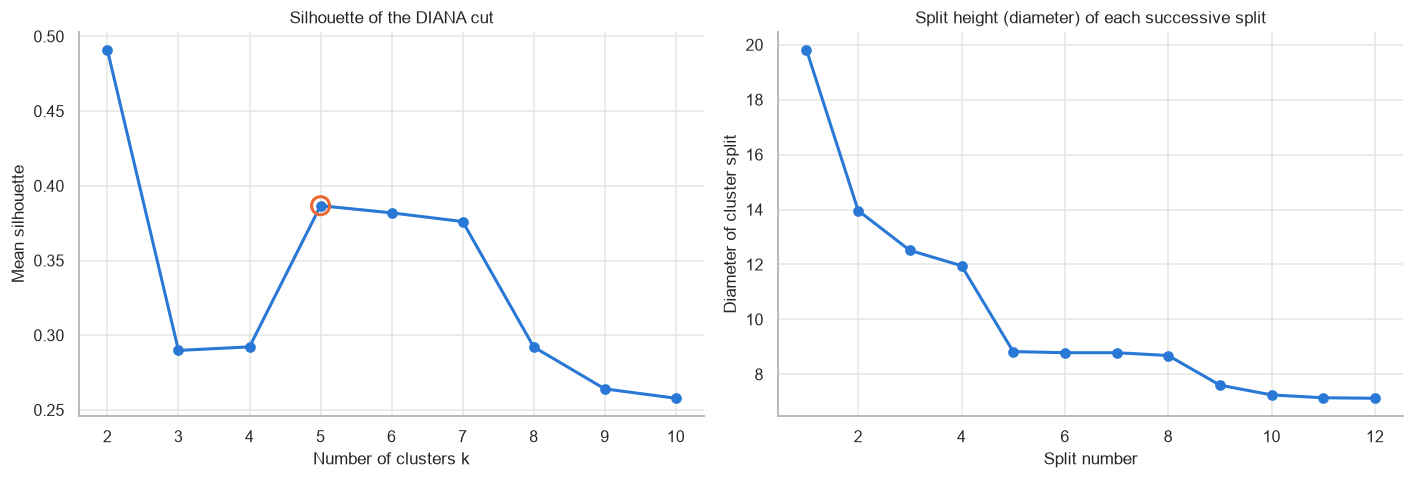

Silhouette: {2: 0.491, 3: 0.29, 4: 0.292, 5: 0.387, 6: 0.382, 7: 0.376, 8: 0.292, 9: 0.264, 10: 0.258}


In [4]:
ks = range(2, 11)
sil = pd.Series({k: silhouette_score(D, cut(res, len(D), k), metric='precomputed') for k in ks})
heights = [s[0] for s in res['splits'][:12]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sil.index, sil.values, marker='o', color=CAT[0], lw=2)
axes[0].scatter([5], [sil[5]], s=140, facecolors='none', edgecolors=CAT[1], linewidths=2, zorder=3)
axes[0].set(title='Silhouette of the DIANA cut', xlabel='Number of clusters k', ylabel='Mean silhouette')
axes[1].plot(range(1, len(heights)+1), heights, marker='o', color=CAT[0], lw=2)
axes[1].set(title='Split height (diameter) of each successive split', xlabel='Split number', ylabel='Diameter of cluster split')
fig.tight_layout(); save_fig('26_diana_choose_k'); plt.show()
print('Silhouette:', sil.round(3).to_dict())

**Inferences:**
- **Two clusters gave the clearest broad division** (silhouette 0.491): the 73 hot-season days vs the rest of the year.
- **We selected five to describe finer day types**, supported by a local silhouette maximum (0.387 at k = 5) and a drop in split height after the 4th split (11.95 → 8.83).
- The k = 5 maximum is narrow: k = 6 (0.382) and k = 7 (0.376) score almost the same. k = 5 is a descriptive choice, not a uniquely optimal one.

## 4. Dendrogram

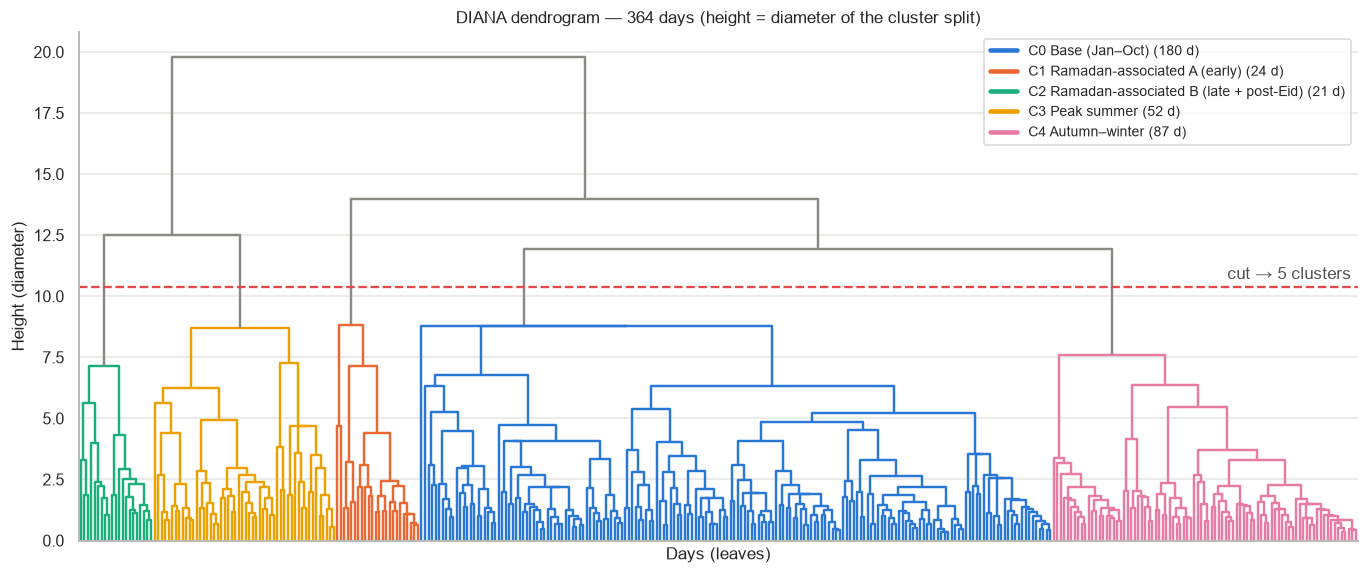

In [5]:
K = 5
labels = cut(res, len(D), K)
thr = (heights[K-2] + heights[K-1]) / 2                       # cut between the 4th and 5th split
assert len(set(zip(labels, fcluster(res['linkage'], K, 'maxclust')))) == K   # same partition as SciPy cut

NAMES = {0: 'Base (Jan–Oct)', 1: 'Ramadan-associated A (early)', 2: 'Ramadan-associated B (late + post-Eid)', 3: 'Peak summer', 4: 'Autumn–winter'}   # named after reading the table above
COL = dict(zip(range(K), CAT[:K]))
# Colour each link by its cluster (gray above the cut) so colours match every other plot
n, Z = len(D), res['linkage']
leaves = {i: {i} for i in range(n)}
for j, row in enumerate(Z):
    leaves[n + j] = leaves[int(row[0])] | leaves[int(row[1])]
def link_col(i):
    labs = {labels[l] for l in leaves[i]}
    return COL[labs.pop()] if len(labs) == 1 else '#8a8984'

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z, link_color_func=link_col, no_labels=True, ax=ax)
ax.legend(handles=[plt.Line2D([], [], color=COL[c], lw=3) for c in range(K)],
          labels=[f'C{c} {NAMES[c]} ({(labels == c).sum()} d)' for c in range(K)], loc='upper right', fontsize=9)
ax.axhline(thr, color=CAT[7], ls='--', lw=1.5)
ax.text(ax.get_xlim()[1]*0.995, thr*1.03, f'cut → {K} clusters', ha='right', color='#52514e')
ax.set(title=f'DIANA dendrogram — 364 days (height = diameter of the cluster split)', xlabel='Days (leaves)', ylabel='Height (diameter)')
save_fig('27_diana_dendrogram'); plt.show()

**Inferences:**
- The first (highest) split, at diameter 19.8, separates the **hot season** (73 days) from the rest of the year → season is the dominant structure.
- Divisive coefficient **0.932** (close to 1 = strong cluster structure); cophenetic correlation **0.817** (the tree preserves the original day-to-day distances well).
- Below the cut, the large blue and pink groups are compact; the two Ramadan-associated groups have more internal spread.

## 5. Robustness — raw kW vs zone-scaled
If the structure is real, it should not depend much on the scaling choice.

In [6]:
res_raw = diana(squareform(pdist(X_raw)))
lab_raw = cut(res_raw, len(D), K)
D_raw = squareform(pdist(X_raw))
robust = pd.DataFrame({
    'Zone-scaled (chosen)': [res['dc'], coph, silhouette_score(D, labels, metric='precomputed'), np.bincount(labels).tolist()],
    'Raw kW': [res_raw['dc'], cophenet(res_raw['linkage'], pdist(X_raw))[0],
               silhouette_score(D_raw, lab_raw, metric='precomputed'), np.bincount(lab_raw).tolist()]},
    index=['Divisive coefficient', 'Cophenetic correlation', f'Silhouette (k={K})', 'Cluster sizes'])
print(f'Agreement between the two k={K} partitions (Adjusted Rand Index): {adjusted_rand_score(labels, lab_raw):.3f}')
robust

Agreement between the two k=5 partitions (Adjusted Rand Index): 0.854


,Zone-scaled (chosen),Raw kW
Divisive coefficient,0.932228,0.932785
Cophenetic correlation,0.817317,0.821073
Silhouette (k=5),0.386695,0.387538
Cluster sizes,"[180, 24, 21, 52, 87]","[170, 17, 22, 55, 100]"


**Inference:** raw kW and zone-scaled inputs give almost the same tree (DC 0.932 vs 0.933, silhouette 0.387 vs 0.388) and the same partition (**ARI 0.854**). The clusters are not an artefact of the scaling choice; zone scaling is kept because it weights the three zones equally.

## 6. Interpreting the clusters

In [7]:
d['cluster'] = labels
d['weekend'] = (d.day_type == 'Weekend').astype(int)
prof = d.groupby('cluster').agg(
    days=('date', 'size'), first_day=('date', 'min'), last_day=('date', 'max'),
    top_months=('month', lambda s: ', '.join(f'{m}:{c}' for m, c in s.value_counts().head(3).items())),
    weekend_share=('weekend', 'mean'), ramadan_days=('is_ramadan', 'sum'), eid_days=('eid_period', 'sum'),
    temp_mean=('temp_mean', 'mean'), city_mean_kW=('daily_mean', 'mean'), load_factor=('load_factor', 'mean'),
    peak_hour=('peak_hour', lambda s: s.mode().iat[0]))
for k in (1, 2, 3):
    prof[f'Z{k} @20h'] = d.groupby('cluster')[f'z{k}_h20'].mean()
prof[f'Z1 @03h'] = d.groupby('cluster')['z1_h03'].mean()
prof.round(2)

/var/folders/z2/c4nry4sj4wncfltdrb9d9rxm0000gn/T/ipykernel_17101/4182759403.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['cluster'] = labels
/var/folders/z2/c4nry4sj4wncfltdrb9d9rxm0000gn/T/ipykernel_17101/4182759403.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['weekend'] = (d.day_type == 'Weekend').astype(int)
/var/folders/z2/c4nry4sj4wncfltdrb9d9rxm0000gn/T/ipykernel_17101/4182759403.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  prof.r

,days,first_day,last_day,top_months,weekend_share,ramadan_days,eid_days,temp_mean,city_mean_kW,load_factor,peak_hour,Z1 @20h,Z2 @20h,Z3 @20h,Z1 @03h
cluster,,,,,,,,,,,,,,,
0,180,2017-01-01,2017-10-22,"1:31, 3:31, 4:30",0.29,0,8,16.57,67690.08,0.71,20,43787.95,25626.73,25215.16,23692.24
1,24,2017-05-25,2017-08-29,"6:15, 5:7, 8:2",0.29,18,2,21.77,73581.28,0.72,20,44985.50,26683.62,27682.59,32113.34
2,21,2017-06-13,2017-08-27,"6:15, 7:4, 8:2",0.38,12,5,23.29,78062.77,0.73,20,45877.31,27948.86,31483.01,32034.33
3,52,2017-07-04,2017-08-25,"7:27, 8:25",0.21,0,0,26.73,88951.40,0.72,20,49012.94,32768.73,40022.42,29617.51
4,87,2017-09-14,2017-12-30,"11:30, 12:30, 10:24",0.23,0,0,16.80,65638.51,0.72,18,39975.21,31217.45,17570.45,22700.25


In [8]:
# Where did the 30 Ramadan days go? (DIANA never saw this label)
cov = pd.crosstab(d.cluster.map(lambda c: f'C{c}'), d.is_ramadan.map({0: 'other days', 1: 'Ramadan days'}), margins=True)
cov

is_ramadan,Ramadan days,other days,All
cluster,,,
C0,0,180,180
C1,18,6,24
C2,12,9,21
C3,0,52,52
C4,0,87,87
All,30,334,364


/var/folders/z2/c4nry4sj4wncfltdrb9d9rxm0000gn/T/ipykernel_17101/4258145791.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  d['cluster_name'] = d.cluster.map(NAMES)


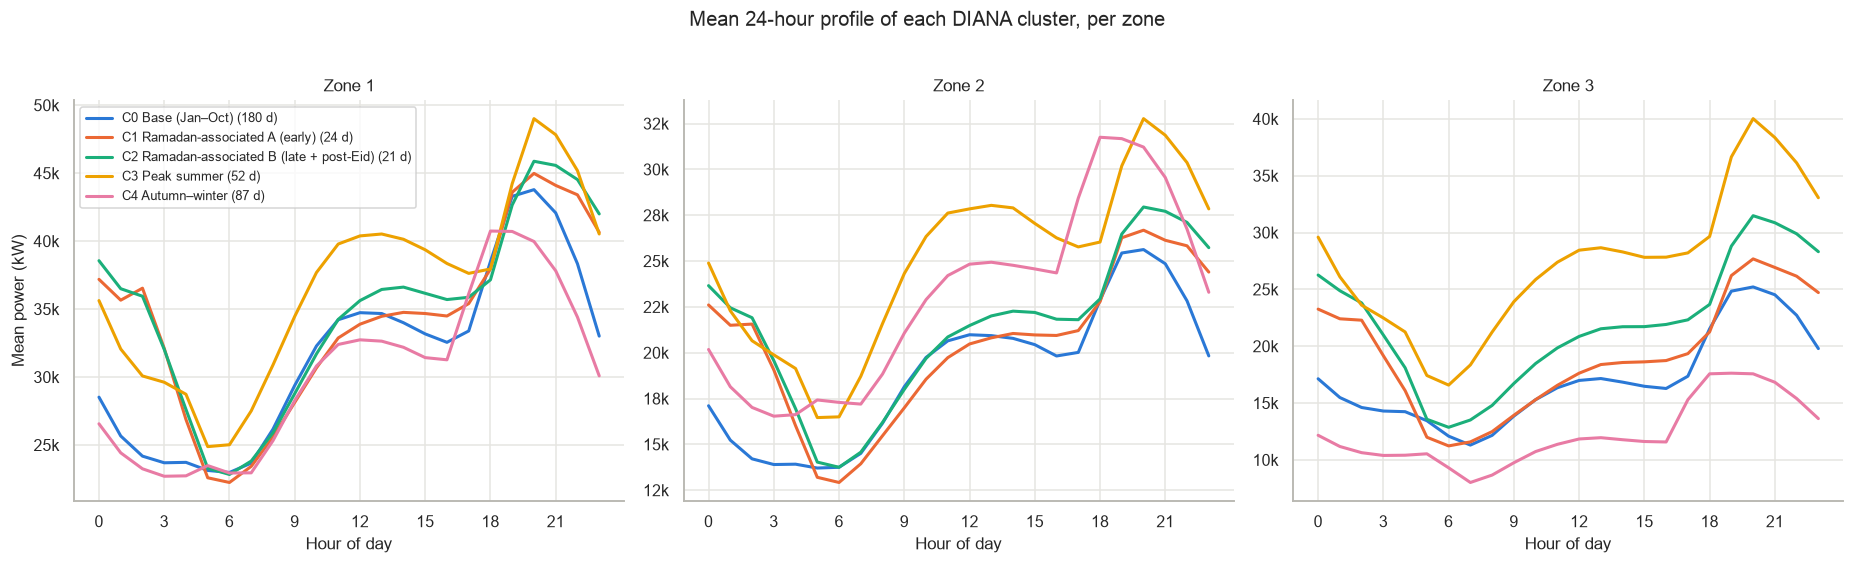

In [9]:
d['cluster_name'] = d.cluster.map(NAMES)
hours = np.arange(24)
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=False)
for k, ax in zip((1, 2, 3), axes):
    for c in range(K):
        prof_c = d.loc[d.cluster == c, [f'z{k}_h{h:02d}' for h in hours]].mean()
        ax.plot(hours, prof_c.values, color=COL[c], lw=2, label=f'C{c} {NAMES[c]} ({(d.cluster == c).sum()} d)')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v/1000:.0f}k'))
    ax.set(title=f'Zone {k}', xlabel='Hour of day', xticks=range(0, 24, 3), ylabel='Mean power (kW)' if k == 1 else '')
axes[0].legend(loc='upper left', fontsize=8.5)
fig.suptitle('Mean 24-hour profile of each DIANA cluster, per zone', y=1.02, fontsize=13)
fig.tight_layout(); save_fig('28_diana_cluster_profiles'); plt.show()

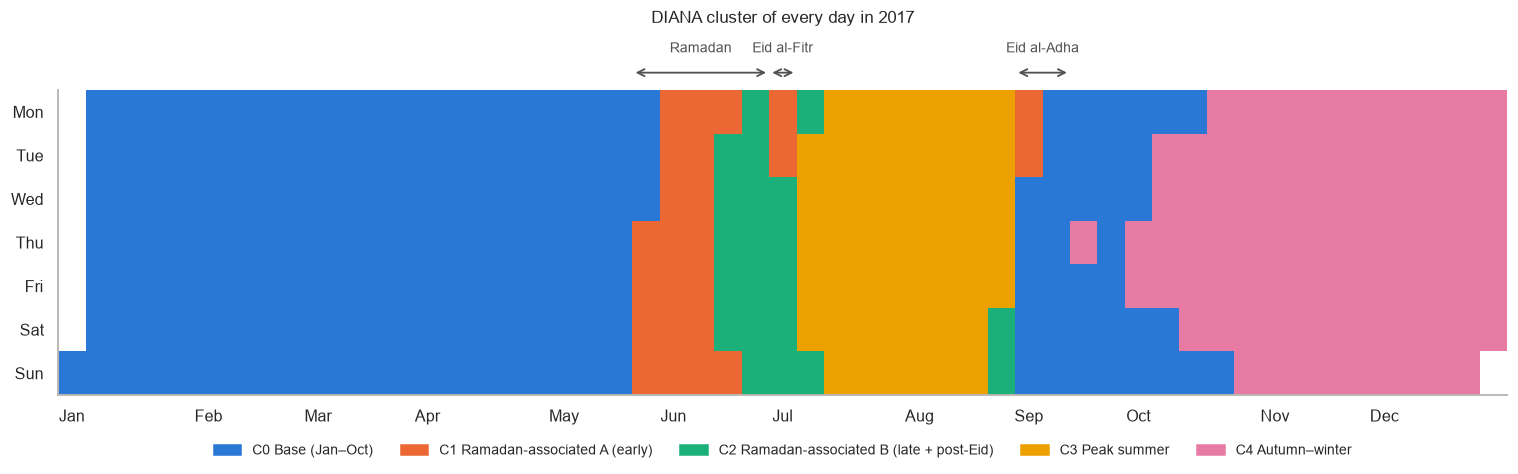

In [10]:
# Calendar: which cluster each day belongs to (rows = weekday, columns = week of year)
cal = np.full((7, 53), np.nan)
wk = ((d.date - pd.Timestamp('2017-01-02')).dt.days // 7 + 1).clip(lower=0)   # Mon-start weeks; 1 Jan = week 0
cal[d.date.dt.dayofweek.values, wk.values] = d.cluster.values
fig, ax = plt.subplots(figsize=(17, 3.6))
ax.imshow(cal, aspect='auto', cmap=ListedColormap(CAT[:K]), vmin=-0.5, vmax=K-0.5, interpolation='none')
ax.set_yticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
month_start = [((pd.Timestamp(2017, m, 1) - pd.Timestamp('2017-01-02')).days // 7 + 1) for m in range(1, 13)]
ax.set_xticks(month_start, ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
for x0, x1, lab in [('2017-05-27', '2017-06-25', 'Ramadan'), ('2017-06-26', '2017-07-02', 'Eid al-Fitr'), ('2017-08-30', '2017-09-06', 'Eid al-Adha')]:
    a, b = [((pd.Timestamp(v) - pd.Timestamp('2017-01-02')).days // 7 + 1) for v in (x0, x1)]
    ax.annotate('', xy=(a - 0.5, -0.9), xytext=(b + 0.5, -0.9), arrowprops=dict(arrowstyle='<->', color='#52514e', lw=1.2), annotation_clip=False)
    ax.text((a + b)/2, -1.3, lab, ha='center', va='bottom', fontsize=9, color='#52514e', clip_on=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CAT[c]) for c in range(K)], labels=[f'C{c} {NAMES[c]}' for c in range(K)],
          loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=K, frameon=False, fontsize=9)
ax.set_title('DIANA cluster of every day in 2017', pad=44)
ax.grid(False)
save_fig('29_diana_calendar'); plt.show()

**Inferences — five day types (cluster numbers = order of first day):**
- **C0 Base (180 days, Jan–mid-Oct)**: mild (16.6 °C), 67.7k kW, evening peak at 20:00. Also contains the **Eid al-Adha week**: demand falls to base level then (possibly holiday travel — not tested).
- **All 30 Ramadan days fell into two clusters, C1 and C2, although DIANA never saw the calendar label** (table above). These are *Ramadan-associated* profiles, not pure Ramadan clusters: they also hold 15 other days.
  - **C1 Ramadan-associated A (24 days, 18 Ramadan)**: mostly 27 May–12 Jun, plus the Eid al-Fitr days, 25–26 May and 28–29 Aug. Zone 1 at 03:00 = **32.1k vs 23.7k kW** in Base (+36 %).
  - **C2 Ramadan-associated B (21 days, 12 Ramadan)**: mostly 13–25 Jun plus the week after Eid (28 Jun–3 Jul) and a few summer days. Same night pattern, but hotter (23.3 °C) with higher Zone 3 evening load (31.5k).
  - Possible explanations (not tested here): pre-dawn *suhoor* meals raising night demand, holiday travel around Eid, and early-summer tourism in Zone 3.
- **C3 Peak summer (52 days, 4 Jul–25 Aug)**: 26.7 °C, 89.0k kW (+31 % vs Base). Zone 3 at 20:00 = **40.0k kW (1.6× Base)** → coastal tourism plus cooling; nights also stay high.
- **C4 Autumn–winter (87 days, mid-Sep–Dec)**: Zone 3 drops to 17.6k at 20:00 while Zone 2 rises to 31.2k, and the peak moves to **18:00** (early sunset). Only the 72-column zone profile can see this zone swap.
- **Weekends never form their own cluster** (weekend share 21–38 % in every cluster) → day-of-week effects are smaller than season and Ramadan effects.

## 7. Cluster quality — silhouette of every day

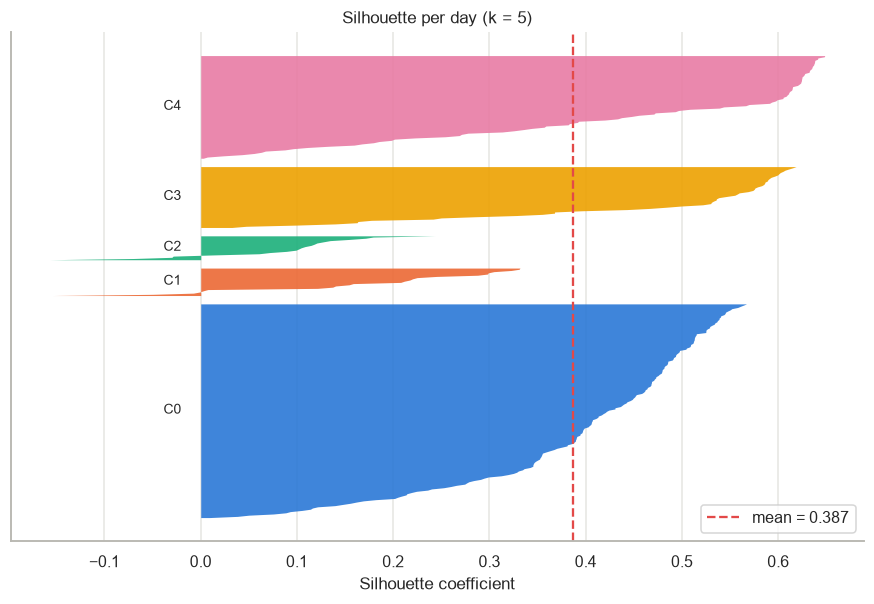

Mean silhouette per cluster: {0: 0.398, 1: 0.167, 2: 0.082, 3: 0.467, 4: 0.449}
Days with negative silhouette: 8


In [11]:
s_val = silhouette_samples(D, labels, metric='precomputed')
fig, ax = plt.subplots(figsize=(10, 6))
y = 0
for c in range(K):
    v = np.sort(s_val[labels == c])
    ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, color=COL[c], alpha=0.9, lw=0)
    ax.text(-0.02, y + len(v)/2, f'C{c}', ha='right', va='center', fontsize=9)
    y += len(v) + 6
ax.axvline(s_val.mean(), color=CAT[7], ls='--', lw=1.5, label=f'mean = {s_val.mean():.3f}')
ax.set(title=f'Silhouette per day (k = {K})', xlabel='Silhouette coefficient', yticks=[])
ax.legend(loc='lower right')
save_fig('30_diana_silhouette'); plt.show()
print('Mean silhouette per cluster:', pd.Series(s_val).groupby(labels).mean().round(3).to_dict())
print('Days with negative silhouette:', int((s_val < 0).sum()))

**Inferences:**
- Peak summer (0.467), Autumn–winter (0.449) and Base (0.398) are well separated.
- The two Ramadan-associated clusters are weak (0.167, 0.082), and all 8 negative-silhouette days sit there. These days look **transitional**: they share a night pattern, but their daytime load lies between Base and Summer, so the boundary between C1 and C2 is not sharp.

## 8. Next split (k = 6) — what DIANA separates next

In [12]:
lab6 = cut(res, len(D), 6)
new = [c for c in range(6) if not any(set(np.where(lab6 == c)[0]) == set(np.where(labels == k)[0]) for k in range(K))]
small = min(new, key=lambda c: (lab6 == c).sum())
days6 = d.loc[lab6 == small, ['date', 'day_type', 'is_ramadan', 'eid_period', 'daily_mean', 'peak_hour']]
print(f'Split 5 separates {len(days6)} day(s) from their cluster:')
days6

Split 5 separates 2 day(s) from their cluster:


,date,day_type,is_ramadan,eid_period,daily_mean,peak_hour
176,2017-06-26,Holiday,0,1,71989.821671,0
177,2017-06-27,Holiday,0,1,68513.859608,22


**Inference:** the 5th split isolates exactly the **two Eid al-Fitr days (26–27 June)**. On 26 June the daily peak falls at **00:00**, unlike any other cluster (possibly night-time activity at the end of Ramadan — not tested). DIANA's splinter step separated these unusual days without being given a holiday label.

In [13]:
d[['date', 'cluster', 'cluster_name', 'season', 'day_type', 'is_ramadan', 'eid_period']].to_csv(OUTPUTS / 'diana_day_clusters.csv', index=False)
print('Saved outputs/diana_day_clusters.csv')

Saved outputs/diana_day_clusters.csv


## 9. Summary

| Aspect | Result |
|---|---|
| Choice | DIANA (data has no class label → unsupervised clustering is the relevant technique) |
| Input | 364 days × 72 zone-hour means, zone-wise z-score, Euclidean distance (≈ 1 MB matrix) |
| Validation | same partition as SciPy `fcluster` on our tree |
| Quality | DC 0.932, cophenetic 0.817, silhouette 0.387 (k = 5); robust to scaling (ARI 0.854) |
| k | 2 gives the clearest broad split (0.491); 5 chosen for finer day types (local silhouette maximum 0.387 + split-height drop) |
| Clusters | Base · Ramadan-associated A · Ramadan-associated B · Peak summer · Autumn–winter |
| Key findings | season is the first split; all 30 Ramadan days fall into two clusters without the label; Zone 3 ↔ Zone 2 swap after summer; Eid al-Fitr isolated at the next split; weekends not a separate day type |
| Limitation | Ramadan-associated clusters have weak silhouettes (0.17, 0.08) and include 15 non-Ramadan days; k = 5 is narrowly ahead of k = 6–7 |